# Read Between the Weights
## A small model with a repairable weakness

This notebook explains the synthetic classifier, summarizes its training pilot, and shows how a controlled weight change creates a weakness. The figures use the **validation set**, not the private final evaluation set. The repair is a known sanity check, not a reviewer discovery.

Run from the project environment, with this repository as the notebook's working directory or its parent. The notebook exports reusable PNG and SVG figures to `results/figures/`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiment.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'experiment.json').exists():
    raise FileNotFoundError('Open this notebook from the project root or notebooks/ directory.')
sys.path.insert(0, str(ROOT / 'src'))
from weight_reader.data import make_split
from weight_reader.model import WeightReaderMLP
from weight_reader.editing import edit_weights, validation_metrics

torch.set_num_threads(1)
config = json.loads((ROOT / 'experiment.json').read_text())
metrics = pd.read_json(ROOT / 'results' / 'training_pilot.json')
x_val, y_val = make_split(**config['splits']['validation'])
def load_model(filename):
    model = WeightReaderMLP()
    model.load_state_dict(torch.load(ROOT / 'checkpoints' / filename, map_location='cpu', weights_only=True))
    return model.eval()
reference = load_model('trained_seed_11.pt')
starting = load_model('editing_start_seed_11.pt')
# This known repair undoes the deliberately introduced fault; it is not a reviewer finding.
repaired = edit_weights(starting, 'fc2.weight', [None, 5], 2.0).eval()
OUT = ROOT / 'results' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white'})
def export(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight', facecolor='white')
    fig.savefig(OUT / f'{name}.svg', bbox_inches='tight', facecolor='white')
print(f'Validation samples: {len(x_val):,}; inputs: {x_val.shape[1]}; parameters: {sum(p.numel() for p in reference.parameters())}')

Validation samples: 1,024; inputs: 4; parameters: 121


## 1. Task and architecture

Each example has four independent inputs in [−1, 1]. The label is **1 when x₀ and x₁ have the same sign**, otherwise 0. Away from zero, this is an **XNOR of the sign bits**: the answer is 1 when both inputs are positive or both are negative. If either input is exactly zero, the label is defined as 0; zero has probability zero under the continuous input distribution. The other two inputs are nuisance variables. The model returns a logit: positive predicts class 1; zero or negative predicts class 0.

Two nonlinear hidden layers make the network small enough to inspect while allowing neuron effects to pass through another ReLU layer.

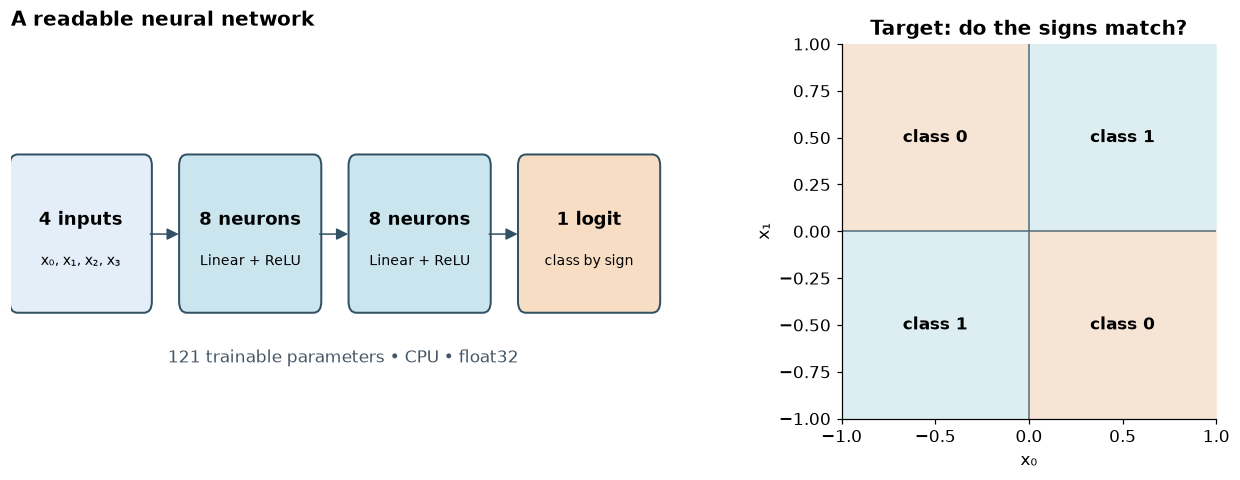

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios':[1.25, 1]})
ax = axes[0]
ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis('off')
blocks = [(0.1, '4 inputs', 'x₀, x₁, x₂, x₃', '#e4eef9'), (2.65, '8 neurons', 'Linear + ReLU', '#cbe5ef'), (5.2, '8 neurons', 'Linear + ReLU', '#cbe5ef'), (7.75, '1 logit', 'class by sign', '#f7ddc4')]
for x, title, sub, color in blocks:
    ax.add_patch(FancyBboxPatch((x, 1.25), 1.9, 1.45, boxstyle='round,pad=0.12', facecolor=color, edgecolor='#315064', linewidth=1.3))
    ax.text(x + .95, 2.12, title, ha='center', va='center', weight='bold', fontsize=12)
    ax.text(x + .95, 1.68, sub, ha='center', va='center', fontsize=9)
for x in (2.05, 4.6, 7.15):
    ax.add_patch(FancyArrowPatch((x, 1.97), (x+.52, 1.97), arrowstyle='-|>', mutation_scale=16, color='#315064'))
ax.text(5, .6, '121 trainable parameters • CPU • float32', ha='center', color='#456')
ax.set_title('A readable neural network', loc='left', pad=12)
ax = axes[1]
for xmin, xmax, ymin, ymax, label, color in [(-1,0,0,1,'class 0','#f6e4d4'),(0,1,0,1,'class 1','#dceef2'),(-1,0,-1,0,'class 1','#dceef2'),(0,1,-1,0,'class 0','#f6e4d4')]:
    ax.fill_between([xmin,xmax], ymin, ymax, color=color)
    ax.text((xmin+xmax)/2,(ymin+ymax)/2,label,ha='center',va='center',weight='bold')
ax.axhline(0,color='#536b78',lw=1); ax.axvline(0,color='#536b78',lw=1)
ax.set(xlim=(-1,1),ylim=(-1,1),xlabel='x₀',ylabel='x₁',title='Target: do the signs match?'); ax.set_aspect('equal')
fig.tight_layout(); export(fig, '01_task_and_architecture'); plt.show()

## 2. Training pilot

Three independently initialized models used the same training and validation sets. Each checkpoint was selected by **minimum validation loss** with early stopping. Accuracy is shown at that selected checkpoint; it is not a held-out final result. The 95% line is the planned pilot target.

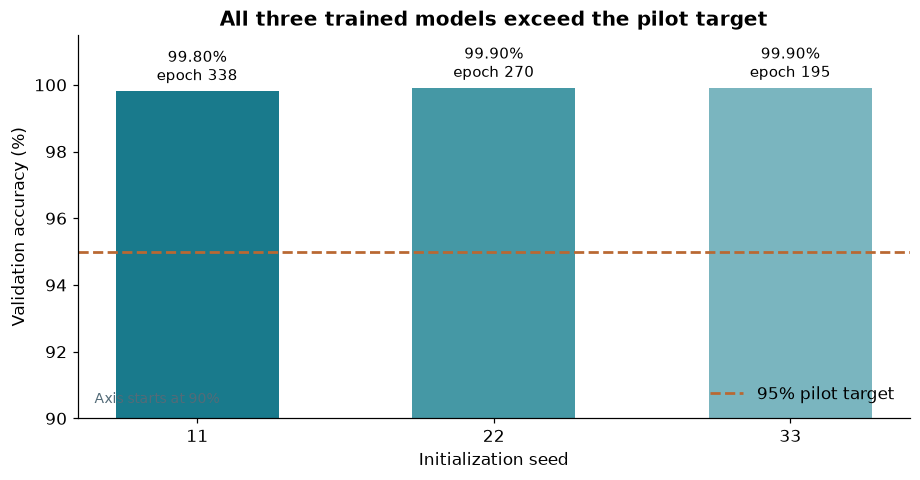

 seed  best_epoch  epochs_run  validation_loss  validation_accuracy  seconds
   11         338         388         0.004984             0.998047 2.058610
   22         270         320         0.004306             0.999023 1.700783
   33         195         245         0.006739             0.999023 1.292284


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = ['#197a8c', '#4598a5', '#7ab5bf']
bars = ax.bar(metrics['seed'].astype(str), metrics['validation_accuracy']*100, color=colors, width=.55)
ax.axhline(95, color='#b96832', linestyle='--', lw=1.8, label='95% pilot target')
for bar, (_, row) in zip(bars, metrics.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.18, f"{row['validation_accuracy']*100:.2f}%\nepoch {int(row['best_epoch'])}", ha='center', va='bottom', fontsize=10)
ax.set(ylim=(90, 101.5), xlabel='Initialization seed', ylabel='Validation accuracy (%)', title='All three trained models exceed the pilot target')
ax.text(.02, .04, 'Axis starts at 90%', transform=ax.transAxes, fontsize=9, color='#536b78')
ax.legend(loc='lower right', frameon=False); fig.tight_layout(); export(fig, '02_training_pilot'); plt.show()
print(metrics[['seed','best_epoch','epochs_run','validation_loss','validation_accuracy','seconds']].to_string(index=False))

## 3. Decision boundaries and the controlled weakness

The left panel shows the target; the center shows the original trained model; the right shows its deliberately weakened copy. To visualize four-dimensional behavior in two dimensions, this slice holds **x₂ = x₃ = 0**. It is illustrative, not an estimate of dataset accuracy.

The weakened checkpoint was constructed by halving one downstream weight column. This makes the task repairable, but the defect is artificial. The construction and original checkpoint must be withheld in a blinded reviewer experiment.

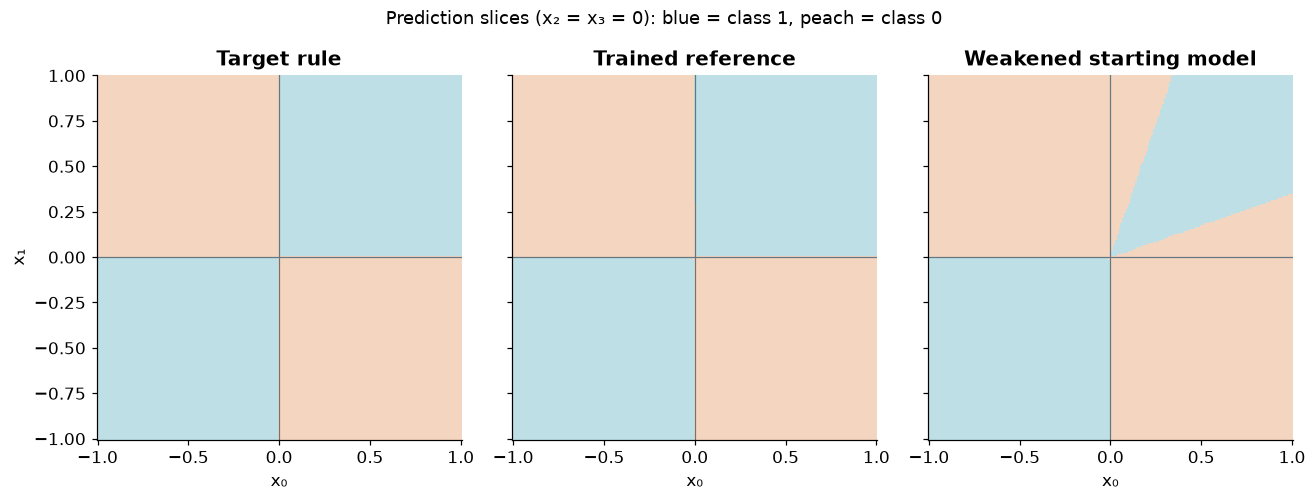

In [4]:
points = np.linspace(-1, 1, 201)
xx, yy = np.meshgrid(points, points)
grid = torch.tensor(np.column_stack([xx.ravel(), yy.ravel(), np.zeros(xx.size), np.zeros(xx.size)]), dtype=torch.float32)
with torch.no_grad():
    reference_pred = (reference(grid).numpy().reshape(xx.shape) > 0)
    starting_pred = (starting(grid).numpy().reshape(xx.shape) > 0)
target = xx * yy > 0
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True)
cmap = ListedColormap(['#f4d5c0', '#bedfe5'])
for ax, values, title in zip(axes, [target, reference_pred, starting_pred], ['Target rule', 'Trained reference', 'Weakened starting model']):
    ax.pcolormesh(xx, yy, values.astype(int), shading='auto', cmap=cmap, vmin=0, vmax=1, rasterized=True)
    ax.axhline(0, color='#667780', lw=.8); ax.axvline(0, color='#667780', lw=.8)
    ax.set_title(title); ax.set_xlabel('x₀'); ax.set_aspect('equal')
axes[0].set_ylabel('x₁')
fig.suptitle('Prediction slices (x₂ = x₃ = 0): blue = class 1, peach = class 0', y=1.02, fontsize=12)
fig.tight_layout(); export(fig, '03_decision_boundaries'); plt.show()

## 4. Performance by quadrant and a known repair

The validation set varies all four inputs. Quadrant accuracy reveals that the degraded model's errors are concentrated in **Q++**, a pattern that aggregate accuracy can hide. The repair below doubles the same weight column that was halved; it is a controlled demonstration that editing can restore performance, not an independently discovered solution.

Validation results support exploration. Repeatedly selecting edits on this set can overfit it, so freeze the final candidate and evaluation procedure before using the private final set.

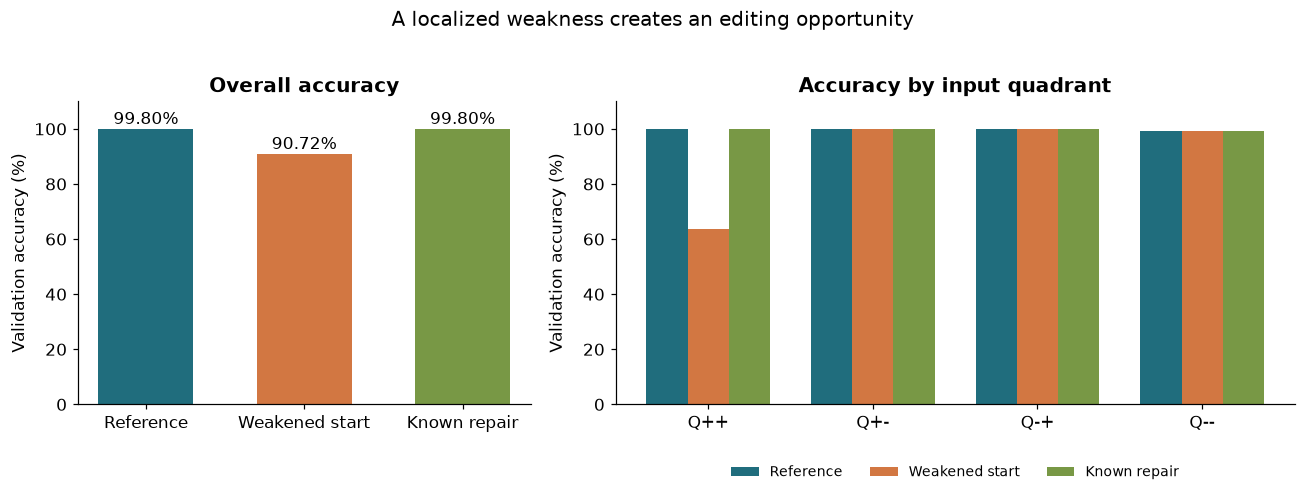

Reference: 99.80% overall; Q++: 100.00% (n=256), Q+-: 100.00% (n=268), Q-+: 100.00% (n=237), Q--: 99.24% (n=263)
Weakened start: 90.72% overall; Q++: 63.67% (n=256), Q+-: 100.00% (n=268), Q-+: 100.00% (n=237), Q--: 99.24% (n=263)
Known repair: 99.80% overall; Q++: 100.00% (n=256), Q+-: 100.00% (n=268), Q-+: 100.00% (n=237), Q--: 99.24% (n=263)


In [5]:
models = {'Reference': reference, 'Weakened start': starting, 'Known repair': repaired}
summary = {name: validation_metrics(model, (x_val, y_val)) for name, model in models.items()}
qnames = ['Q++','Q+-','Q-+','Q--']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios':[1, 1.5]})
colors = ['#206d7d', '#d27742', '#789845']
bars = axes[0].bar(list(models), [summary[n]['accuracy']*100 for n in models], color=colors, width=.6)
for bar in bars:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+.5, f'{bar.get_height():.2f}%', ha='center', va='bottom')
axes[0].set(ylim=(0,110), ylabel='Validation accuracy (%)', title='Overall accuracy')
positions = np.arange(4); width=.25
for i, (name, color) in enumerate(zip(models, colors)):
    vals = [summary[name]['quadrants'][q]['accuracy']*100 for q in qnames]
    axes[1].bar(positions+(i-1)*width, vals, width, label=name, color=color)
axes[1].set(xticks=positions, xticklabels=qnames, ylim=(0,110), ylabel='Validation accuracy (%)', title='Accuracy by input quadrant')
axes[1].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3)
fig.suptitle('A localized weakness creates an editing opportunity', y=1.02, fontsize=13)
fig.tight_layout(); export(fig, '04_weakness_and_repair'); plt.show()
for name, result in summary.items():
    print(f"{name}: {result['accuracy']:.2%} overall; " + ', '.join(f"{q}: {result['quadrants'][q]['accuracy']:.2%} (n={result['quadrants'][q]['count']})" for q in qnames))

## What comes next?

1. Use targeted input probes to form a hypothesis about the observed weakness. Probe feedback should be limited to the permitted model outputs.
2. Propose and freeze a weight edit without access to the original checkpoint or the known fault.
3. Compare the frozen candidate with the weakened starting model on an untouched final evaluation set, including quadrant accuracy and possible regressions.
4. Record unsuccessful edits as well as improvements. A controlled repair does not establish that an LLM can reliably find the repair or generalize to other models.

The `inspect` command is an unbudgeted exploratory interface. The project also provides a budgeted manual probe relay, reviewer packets, and a repair-study freeze and scoring workflow. No reviewer responses have been collected or scored.